In [1]:
import cv2 as cv
import matplotlib.pyplot as plt

from core.entities.constants import Paths as p

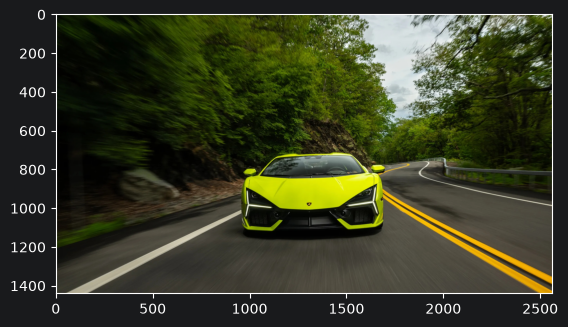

In [2]:
img_path = p.IMAGE_ASSETS / "lambo.jpg"

img = cv.imread(img_path)

img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

plt.figure()
plt.imshow(img_rgb)

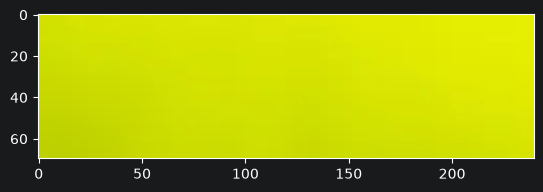

In [3]:
img_region = img_rgb[870:940, 1208:1448, :]
plt.figure()
plt.imshow(img_region)

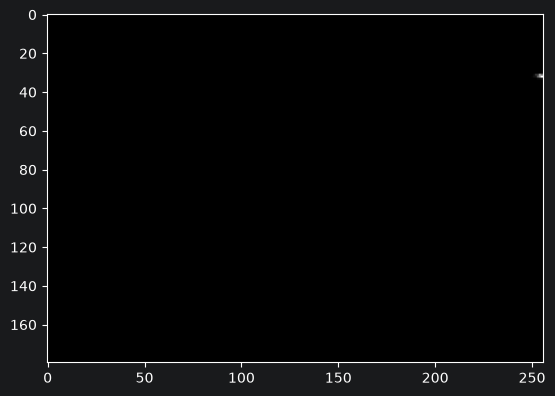

In [4]:
img_region_hsv = cv.cvtColor(img_region, cv.COLOR_RGB2HSV)
img_region_hsv_hist = cv.calcHist([img_region_hsv], [0, 1], None, [180, 256], [0, 180, 0, 256])
cv.normalize(img_region_hsv_hist, img_region_hsv_hist, 0, 255, cv.NORM_MINMAX)

plt.figure()
plt.imshow(img_region_hsv_hist, cmap="gray")



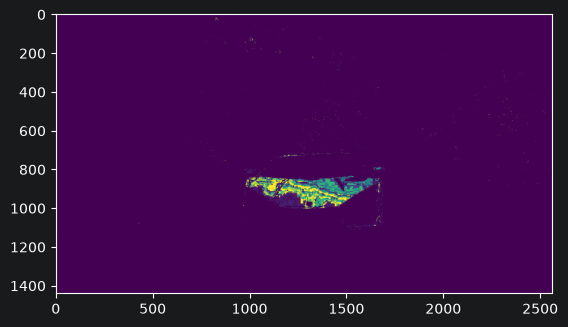

In [5]:
img_hsv = cv.cvtColor(img_rgb, cv.COLOR_RGB2HSV)

out = cv.calcBackProject([img_hsv], [0, 1], img_region_hsv_hist, [0, 180, 0, 256], 1)
plt.figure()
plt.imshow(out)

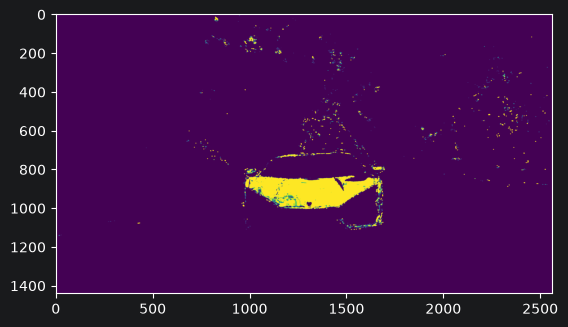

In [6]:
ellipse_Kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (5, 5))
cv.filter2D(out, -1, ellipse_Kernel, out)
plt.figure()
plt.imshow(out)

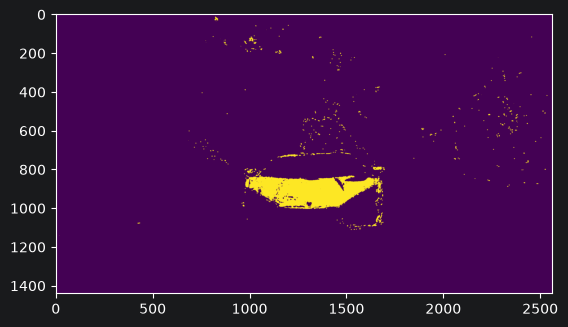

In [7]:
_, mask = cv.threshold(out, 160, 255, cv.THRESH_BINARY)
plt.figure()
plt.imshow(mask)

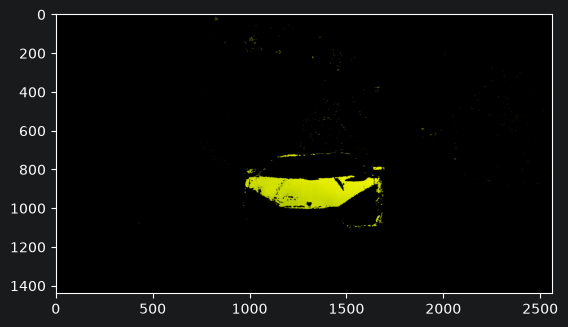

In [8]:
mask_all_channels = cv.merge([mask] * 3)
img_seg = cv.bitwise_and(img_rgb, mask_all_channels)

plt.figure()
plt.imshow(img_seg)